# ДЗ №2 — RAG и память агента

На прошлой неделе агент ходил за фактами в живую Википедию и отвечал на 58 процентов свежих вопросов. Сегодня кладём знания рядом: режем корпус на куски, считаем эмбеддинги, ищем сначала на numpy, потом в Milvus, собираем RAG-ответ с источниками, разбираем провалы и даём агенту память. В конце превращаем поиск в инструмент агента. Дополнение для желающих: тот же конвейер на PDF.

Тезис курса прежний: **хороший агент на дешёвой модели обходится дешевле сильной модели в одиночку при том же качестве.** Сегодняшний вопрос к нему: сколько стоит верный ответ, когда знания лежат в индексе, и сколько в этой цене занимает контекст.

Восемь спринтов, десять дырок. Дырка это функция, у которой вместо тела стоит `...`, ни одна не длиннее десяти строк. Пояснения к дыркам, хронометраж и домашка в `README.md`.

## Что нужно

**Ключ** OpenRouter: локально файл `.env` рядом с ноутбуком, в Kaggle секрет `OPENROUTER_API_KEY` (Add-ons, Secrets, галочка подключения, перезапуск сессии). **Данные**: папка `data` рядом с ноутбуком, в Kaggle датасет `seminar02-data` и включённый Internet.

**Milvus** в Docker: в папке семинара лежит `docker-compose.yml`, команда `docker compose up -d` поднимает базу на `localhost:19530`. Первый запуск скачивает образ, около гигабайта, поэтому сделайте это до семинара. Если Docker поставить нельзя (Kaggle, Colab), в README есть раздел «Нет Docker».

В данных лежит готовый файл эмбеддингов корпуса `embeddings_512.npz`. С ним второй спринт занимает секунды. Без него те же векторы посчитаются через API за цент и минут двадцать: так было у нас при подготовке, и на общей сети аудитории будет не быстрее.

## Подготовка окружения

In [61]:
import os, re, json, time, hashlib, uuid, tiktoken
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import requests, numpy as np, pandas as pd, matplotlib.pyplot as plt
from dotenv import load_dotenv
from pymilvus import MilvusClient
load_dotenv()
DATA=Path('data'); IMG=Path('img'); IMG.mkdir(exist_ok=True)
def read_jsonl(path):
    return [json.loads(x) for x in Path(path).read_text(encoding='utf-8').splitlines() if x.strip()]
def write_jsonl(path, rows):
    Path(path).parent.mkdir(parents=True,exist_ok=True)
    with open(path,'w',encoding='utf-8') as f:
        for row in rows:f.write(json.dumps(row,ensure_ascii=False)+'\n')
def norm(s):return ' '.join(re.findall(r'\w+',str(s).casefold()))
corpus=read_jsonl(DATA/'corpus_2026.jsonl')
tasks=read_jsonl(DATA/'fresh_2026.jsonl')
assert corpus and len(tasks)>=30, 'Нужны документы и ≥30 вопросов с evidence'
assert all(all(q.get(k) for k in ('id','question','answer','evidence','page','url')) for q in tasks)
print('документов:',len(corpus),'подтверждённых вопросов:',len(tasks))

документов: 16 подтверждённых вопросов: 76


### Исходные данные и результаты ДЗ №1

Исходный набор `fresh.jsonl` содержит вопросы предыдущей работы. `check_data.py` формирует `data/fresh_2026.jsonl`: только вопросы, для которых цитаты подтверждены в скачанном корпусе. Количество может отличаться от исходных 145. Для честного сравнения повторно оцениваем прежние и новые конфигурации на **одном и том же подтверждённом наборе**.

Из README первой работы (старый прогон на 145 вопросах):

| Конфигурация | Доля верных | Цена верного ответа, $ |
|---|---:|---:|
| GPT-4o mini, только поиск | 0.16 | 0.00336 |
| GPT-4o mini, поиск и чтение | 0.19 | 0.00393 |
| Claude Sonnet 4.6, без инструментов | 0.03 | 0.14160 |
| Claude Haiku 4.5, поиск и чтение | 0.41 | 0.03412 |

## Шаг 1. Корпус и вопросы

**Нарезки:** `chars` — каждые 400 символов без учёта границ; `structure` — строки исходных страниц, а длинные абзацы делятся по предложениям. Граница проходит по смысловому абзацу/предложению, чтобы не разрывать факт и ближайший контекст.

**Важно:** исходное `evidence` может не помещаться целиком в один 400-символьный кусок. Для recall фиксируем **достаточно ли фрагмента для ответа**, а не требуем полного совпадения длинной цитаты. Правило ниже — автоматическая эвристика, спорные совпадения проверяются вручную.

In [2]:
def chunk_lines(page):
    chunks, section = [], ""
    for line in page["text"].splitlines():
        line = " ".join(line.split())
        if line.startswith("="):
            section = line.strip("= ")
        elif len(line) > 40:
            chunks.append({"page": page["page"], "section": section,
                           "url": page["url"], "text": line})
    return chunks

def chunk_chars(page, size=400):
    text = " ".join(page["text"].split())
    return [{"page": page["page"], "section": "", "url": page["url"],
             "text": text[i:i+size]} for i in range(0, len(text), size)]

line_chunks = [c for doc in corpus for c in chunk_lines(doc)]
char_chunks = [c for doc in corpus for c in chunk_chars(doc)]
chunks = {"structure": line_chunks, "chars": char_chunks}
print("Число фрагментов:", {name: len(rows) for name, rows in chunks.items()})
assert all(len(rows) >= 300 for rows in chunks.values()), "Для обеих нарезок требуется >=300 фрагментов"
assert all(all(k in c for k in ("page", "section", "url", "text")) for rows in chunks.values() for c in rows)
for name, rows in chunks.items():
    write_jsonl(DATA / f"chunks_{name}.jsonl", rows)
source_texts = {d["page"]: norm(d["text"]) for d in corpus}
missing_evidence = [q["id"] for q in tasks if norm(q["evidence"]) not in source_texts.get(q["page"], "")]
assert not missing_evidence, f"Не найдены evidence в документах: {missing_evidence[:10]}"
print("Цитаты evidence присутствуют в источниках")

Число фрагментов: {'structure': 1804, 'chars': 717}
Цитаты evidence присутствуют в источниках


### Проверяем разрыв цитаты и распределение длин

Вопрос: On what date did Ukraine boycott the closing ceremony of the 2026 Winter Paralympics? | ответ: 15 March
Кусок 1: ...ic partnership agreement in the defense and energy sectors. 15 March – Ukraine boycotts the closing ceremony of the 2026 Winter Paralympics in Italy in protest 
Кусок 2: over Russian athletes being allowed to compete under the Russian flag after the lifting of sanctions imposed over the Russian invasion in 2022. 19 March – Forme...


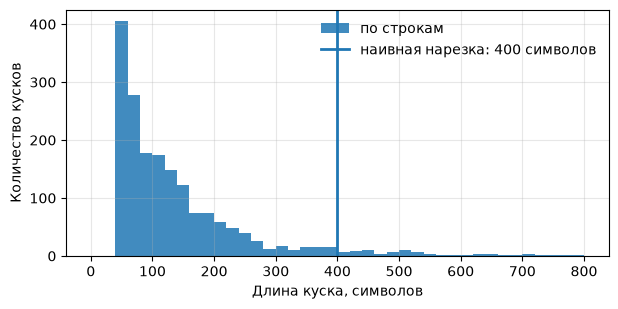

In [3]:
def torn(task):
    words = re.findall(r"\w+", task["evidence"].lower())
    if len(words) < 12:
        return None
    head, tail = " ".join(words[:6]), " ".join(words[-6:])
    parts = [c["text"] for c in char_chunks if c["page"] == task["page"]
             and (head in " ".join(re.findall(r"\w+", c["text"].lower()))
                  or tail in " ".join(re.findall(r"\w+", c["text"].lower())))]
    return parts if len(parts) == 2 else None

example = next((t for t in tasks if torn(t)), None)
if example is None:
    print("Для текущего корпуса пример с двумя частями не найден")
else:
    print("Вопрос:", example["question"], "| ответ:", example["answer"])
    for i, part in enumerate(torn(example), 1):
        print(f"Кусок {i}: ...{part[-160:]}" if i == 1 else f"Кусок {i}: {part[:160]}...")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist([len(c["text"]) for c in line_chunks], bins=40, range=(0, 800),
        alpha=0.85, label="по строкам")
ax.axvline(400, lw=2, label="наивная нарезка: 400 символов")
ax.set_xlabel("Длина куска, символов")
ax.set_ylabel("Количество кусков")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.savefig(IMG / "chunk_lengths.png", dpi=160, bbox_inches="tight")
plt.show()

In [5]:
UNANSWERABLE = [
    "Who won the 2026 Formula One World Drivers' Championship?",
    "Which country won the Eurovision Song Contest 2027?",
    "Which film won the Palme d'Or at the 2027 Cannes Film Festival?",
    "What was the magnitude of the earthquake that struck Lisbon in December 2026?",
    "Which company first reached a ten trillion dollar valuation in November 2026?",
    "Who won the 2026 World Chess Championship match in December 2026?",
    "What were the names of the judges at every 2026 Winter Olympics event?",
    "How many printed tickets were sold at each venue of the 2026 Winter Olympics?",
    "What was the attendance at every single concert in Rome during 2026?",
    "Which weather station recorded the highest hourly humidity in Nepal in August 2026?"
]
assert len(UNANSWERABLE) == 10
pd.DataFrame({'candidate_question': UNANSWERABLE, 'confirmed_absent_from_corpus': [False]*10})

,candidate_question,confirmed_absent_from_corpus
0,Who won the 2026 Formula One World Drivers' Ch...,False
1,Which country won the Eurovision Song Contest ...,False
2,Which film won the Palme d'Or at the 2027 Cann...,False
3,What was the magnitude of the earthquake that ...,False
4,Which company first reached a ten trillion dol...,False
5,Who won the 2026 World Chess Championship matc...,False
6,What were the names of the judges at every 202...,False
7,How many printed tickets were sold at each ven...,False
8,What was the attendance at every single concer...,False
9,Which weather station recorded the highest hou...,False


## Шаг 2. Эмбеддинги, Milvus, recall@k и гибрид

In [6]:
KEY=os.getenv('OPENROUTER_API_KEY')
CHAT_URL='https://openrouter.ai/api/v1/chat/completions';EMBED_URL='https://openrouter.ai/api/v1/embeddings'
HEADERS={'Authorization':f'Bearer {KEY}','X-Title':'HW2-RAG-memory'}
MODELS={'cheap':'openai/gpt-4o-mini','mid':'anthropic/claude-haiku-4.5','strong':'anthropic/claude-sonnet-4.6'}
EMBED_MODEL='openai/text-embedding-3-small';DIM=512
LEDGER=[]; CACHE_PATH=DATA/'embedding_cache_512.npz';CACHE={}
if CACHE_PATH.exists():
    with np.load(CACHE_PATH,allow_pickle=False) as z:
        CACHE={str(k):v.astype(np.float32) for k,v in zip(z['keys'],z['vectors'])}
def post(url,payload):
    for attempt in range(4):
        try:
            r=requests.post(url,json=payload,headers=HEADERS,timeout=120)
            if r.ok:return r.json()
            if r.status_code not in (429,500,502,503,504):r.raise_for_status()
        except requests.RequestException:
            if attempt==3:raise
        time.sleep(2*(attempt+1))
    raise RuntimeError('API did not respond')
def key_of(text):return hashlib.sha256((EMBED_MODEL+':'+str(DIM)+':'+text).encode()).hexdigest()
def save_cache():
    if not CACHE:return
    tmp=CACHE_PATH.with_name('embedding_cache_tmp.npz')
    np.savez_compressed(tmp,keys=np.asarray(list(CACHE)),vectors=np.stack(list(CACHE.values())))
    tmp.replace(CACHE_PATH)
def embed(texts):
    if not texts:return np.empty((0,DIM),dtype=np.float32)
    missing=list(dict.fromkeys(t for t in texts if key_of(t) not in CACHE))
    for i in range(0,len(missing),64):
        batch=missing[i:i+64]; response=post(EMBED_URL,{'model':EMBED_MODEL,'dimensions':DIM,'input':batch})
        ordered=sorted(response['data'],key=lambda row:row['index'])
        assert len(ordered)==len(batch)
        for t,r in zip(batch,ordered):CACHE[key_of(t)]=np.asarray(r['embedding'],dtype=np.float32)
        LEDGER.append({'tag':'embedding','model':EMBED_MODEL,'cost':float((response.get('usage') or {}).get('cost') or 0),'prompt_tokens':(response.get('usage') or {}).get('prompt_tokens',0)})
        save_cache()
    mat=np.stack([CACHE[key_of(t)] for t in texts]);return mat/np.maximum(np.linalg.norm(mat,axis=1,keepdims=True),1e-12)
vecs={kind:embed([c['page']+': '+c['text'] for c in rows]) for kind,rows in chunks.items()}
q_vecs=embed([q['question'] for q in tasks]);print('векторов в кэше:',len(CACHE))

векторов в кэше: 2569


### Контроль эмбеддингов и дискового кэша

In [7]:
probe_texts = [
    "Apple is a big technological company in USA",
    "Green apple is a tasty food from my garden",
    "What was the weather in Tokyo yesterday?",
]
ledger_before = len(LEDGER)
probe = embed(probe_texts)
save_cache()
print("Попарная косинусная близость:\n", (probe @ probe.T).round(2))
print("Новых записей учёта для первого вызова:", len(LEDGER) - ledger_before)
ledger_before = len(LEDGER)
_ = embed(probe_texts)
print("Новых записей учёта при повторном вызове:", len(LEDGER) - ledger_before)

Попарная косинусная близость:
 [[ 1.    0.25 -0.  ]
 [ 0.25  1.    0.03]
 [-0.    0.03  1.  ]]
Новых записей учёта для первого вызова: 1
Новых записей учёта при повторном вызове: 0


In [8]:
MILVUS_URI=os.getenv('MILVUS_URI','http://localhost:19530')
client=MilvusClient(uri=MILVUS_URI)
print('Milvus version:',client.get_server_version())

Milvus version: 2.6.24


In [9]:
def index_collection(name,rows,vectors):
    assert len(rows)==len(vectors)
    if client.has_collection(name):client.drop_collection(name)
    client.create_collection(collection_name=name,dimension=DIM,metric_type='COSINE',enable_dynamic_field=True)
    for start in range(0,len(rows),500):
        batch=[{'id':start+j,'vector':vec.tolist(),**row} for j,(row,vec) in enumerate(zip(rows[start:start+500],vectors[start:start+500]))]
        client.insert(collection_name=name,data=batch)
    client.flush(collection_name=name)
for kind in chunks:index_collection('hw2_'+kind,chunks[kind],vecs[kind])
print('Коллекции:',client.list_collections())

Коллекции: ['hw2_structure', 'hw2_chars']


In [10]:
def search_db(question,kind='structure',k=5,page=''):
    flt=('page == '+json.dumps(page,ensure_ascii=False)) if page else ''
    found=client.search(collection_name='hw2_'+kind,data=embed([question]).tolist(),limit=k,filter=flt,
                        output_fields=['page','section','url','text','ordinal'])[0]
    return [{'id':int(h['id']),'score':float(h['distance']),**h['entity']} for h in found]

In [11]:
page=tasks[0]['page']
filtered=search_db(tasks[0]['question'],page=page)
assert all(h['page']==page for h in filtered)
display(pd.DataFrame(filtered)[['page','section','score','text']].head())

,page,section,score,text
0,2026 in Ukraine,March,0.821284,15 March – Ukraine boycotts the closing ceremo...
1,2026 in Ukraine,March,0.803313,Ukraine boycotts the opening ceremony of the 2...
2,2026 in Ukraine,February,0.674235,6–22 February – Ukraine at the 2026 Winter Oly...
3,2026 in Ukraine,January,0.574957,14 January – President Zelenskyy declares a st...
4,2026 in Ukraine,October,0.556254,8 October – South Korea recalls its ambassador...


In [ ]:
def is_gold(c,q):
    if c['page']!=q['page']:
        return False
    w=norm(q['evidence']).split(); t=norm(c['text']);ans=norm(q['answer'])
    return bool(w and ans) and ans in t and sum(word in t for word in w)>=len(w)*.5
def vec_rank(qv,vectors,k):
    return np.argsort(-(vectors@qv))[:k].tolist()

In [13]:
KS=[1,3,5,10]
def recall_at(rankings,rows,k):
    return float(np.mean([any(is_gold(rows[i],q) for i in rank[:k]) for rank,q in zip(rankings,tasks)]))

In [75]:
rank_vec={kind:[vec_rank(qv,vecs[kind],max(KS)) for qv in q_vecs] for kind in chunks}
recall_df=pd.DataFrame([{'chunking':kind,'k':k,'recall':recall_at(rank_vec[kind],chunks[kind],k)} for kind in chunks for k in KS])
display(recall_df.pivot(index='k',columns='chunking',values='recall'))

chunking,chars,structure
k,,
1,0.500000,0.710526
3,0.684211,0.881579
5,0.736842,0.907895
10,0.842105,0.973684


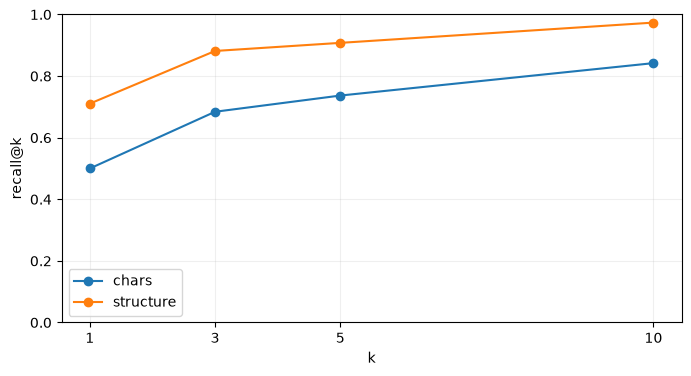

In [74]:
fig, ax = plt.subplots(figsize=(8, 4))

for kind, group in recall_df.groupby("chunking"):
    ax.plot(
        group["k"],
        group["recall"],
        marker="o",
        label=kind
    )

ax.set_xticks([1, 3, 5, 10])
ax.set_ylim(0, 1)
ax.set_xlabel("k")
ax.set_ylabel("recall@k")
ax.legend()
ax.grid(alpha=0.2)

plt.savefig(IMG / "recall_at_k.png", dpi=160, bbox_inches="tight")
plt.show()

In [15]:
BEST_KIND=recall_df[recall_df.k==5].sort_values('recall',ascending=False).iloc[0]['chunking']

In [73]:
K=5  
print('Выбрана нарезка:',BEST_KIND,'k:',K)

Выбрана нарезка: structure k: 5


In [18]:
def tokens(text):
    return set(re.findall(r'\w+',str(text).casefold()))

In [19]:
def keyword_rank(question,rows,n=20):
    doc_words=[tokens(c['text']) for c in rows]
    counts=Counter(word for words in doc_words for word in words)
    query=tokens(question);N=len(rows)
    scores=[sum(np.log((N+1)/(counts[w]+1))+1 for w in query & ws) for ws in doc_words]
    valid=[i for i,s in enumerate(scores) if s>0]
    return sorted(valid,key=lambda i:(-scores[i],i))[:n]

In [20]:
def rrf(rankings,k=5,constant=60):
    scores={}
    for ranking in rankings:
        for rank,i in enumerate(ranking,1):scores[i]=scores.get(i,0)+1/(constant+rank)
    return sorted(scores,key=lambda i:(-scores[i],i))[:k]

In [ ]:
assert rrf([[0,1],[1,0]],2)==[0,1]
keyword_ranks=[keyword_rank(q['question'],chunks[BEST_KIND]) for q in tasks]
vector_ranks=[vec_rank(qv,vecs[BEST_KIND],20) for qv in q_vecs]
hybrid_ranks=[rrf([v,w],10) for v,w in zip(vector_ranks,keyword_ranks)]
hybrid_table=pd.DataFrame([{'method':name,**{f'recall@{k}':recall_at(ranks,chunks[BEST_KIND],k) for k in KS}} for name,ranks in [('vector',vector_ranks),('keywords',keyword_ranks),('RRF hybrid',hybrid_ranks)]])
display(hybrid_table)
hybrid_table.to_csv(DATA/'hybrid_table.csv',index=False)
assert len(hybrid_ranks)==len(tasks)

,method,recall@1,recall@3,recall@5,recall@10
0,vector,0.710526,0.881579,0.907895,0.973684
1,keywords,0.710526,0.828947,0.881579,0.934211
2,RRF hybrid,0.763158,0.921053,0.960526,0.973684


## Шаг 3. RAG, knowledge_base, 5 конфигураций и стоимость

Оценка состоит из **всех подтверждённых вопросов** и отдельно 10 `UNANSWERABLE`. Эксперименты платные; сначала тестируем на 3 вопросах и только затем снимаем ограничение.

In [22]:
def chat(messages,model,tools=None,tag='chat'):
    body={'model':model,'messages':messages,'temperature':0,'usage':{'include':True}}
    if tools:body['tools']=tools
    data=post(CHAT_URL,body);usage=data.get('usage') or {}
    cost=float(usage.get('cost') or 0)
    LEDGER.append({'tag':tag,'model':model,'cost':cost,'prompt_tokens':usage.get('prompt_tokens',0),'completion_tokens':usage.get('completion_tokens',0)})
    return data['choices'][0]['message'],cost

In [32]:
PLAIN = """
Answer the question using your own knowledge.
No external tools or documents are available.

If you know the answer with reasonable confidence,
provide a short factual answer.

If you do not know, reply NOT_FOUND.
Do not invent dates, names or events.

Finish with FINAL: <answer>.
"""

RAG='Use ONLY the numbered sources. Cite sources as [1]. If the answer is absent, say NOT_FOUND. Finish with FINAL: <answer>.'
def final(text):
    found=re.findall(r'FINAL:\s*(.+)',text or '')
    return found[-1].strip() if found else (text or '').strip()
def plain_answer(question,model):
    msg,cost=chat([{'role':'system','content':PLAIN},{'role':'user','content':question}],model,tag='plain')
    return {'answer':msg.get('content') or '', 'hits':[],'cost':cost}
def rag_answer(question,model):
    hits=search_db(question,BEST_KIND,K)
    context='\n'.join(f'[{i}] {h["page"]} / {h["section"]}: {h["text"]} ({h["url"]})' for i,h in enumerate(hits,1))
    msg,cost=chat([{'role':'system','content':RAG},{'role':'user','content':f'Sources:\n{context}\nQuestion: {question}'}],model,tag='rag')
    return {'answer':msg.get('content') or '', 'hits':hits,'cost':cost}
def knowledge_base(query:str,page:str='')->str:
    hits=search_db(query,BEST_KIND,K,page)
    return '\n'.join(f'[{h["page"]} / {h["section"]}] {h["text"]} | {h["url"]}' for h in hits) or 'NOT_FOUND'
TOOL={'type':'function','function':{'name':'knowledge_base','description':'Search local knowledge base of 2026 events. Search before answering factual questions.',
 'parameters':{'type':'object','properties':{'query':{'type':'string'},'page':{'type':'string','description':'optional exact page title'}},'required':['query'],'additionalProperties':False}}}

In [34]:
def agent_answer(question,model,max_steps=4):
    messages=[{'role':'system','content':'You may call knowledge_base. Answer only from retrieved evidence; otherwise NOT_FOUND. Finish with FINAL: <answer>.'},
              {'role':'user','content':question}];cost=0;used=[]
    for _ in range(max_steps):
        msg,c=chat(messages,model,tools=[TOOL],tag='agent');cost+=c;messages.append(msg)
        calls=msg.get('tool_calls') or []
        if not calls:return {'answer':msg.get('content') or '', 'hits':used,'cost':cost}
        for call in calls:
            try:
                args=json.loads(call['function']['arguments']);hits=search_db(args['query'],BEST_KIND,K,args.get('page',''))
                used.extend(hits)
                response='\n'.join(f'[{h["page"]}] {h["text"]} | {h["url"]}' for h in hits) or 'NOT_FOUND'
            except Exception as e:response='TOOL_ERROR: '+str(e)
            messages.append({'role':'tool','tool_call_id':call['id'],'content':response[:6000]})
    msg,c=chat(messages,model,tag='agent_final');cost+=c
    return {'answer':msg.get('content') or '', 'hits':used,'cost':cost}

assert isinstance(knowledge_base(tasks[0]['question']),str)
assert isinstance(knowledge_base(tasks[0]['question'],tasks[0]['page']),str)
assert knowledge_base('test',page='__nonexistent_page__')=='NOT_FOUND'
print('Три теста knowledge_base пройдены без генеративной модели')

Три теста knowledge_base пройдены без генеративной модели


In [35]:
def correct(q,response):
    answer=norm(final(response))
    if 'not_found' in response.casefold() or not answer:return False
    gold=norm(q['answer'])
    return bool(gold and gold in answer) 

In [36]:
def run_eval(name,fn,model,questions):
    rows=[]
    for q in questions:
        try:
            result=fn(q['question'],model);error=''
        except Exception as e:
            result={'answer':'','hits':[],'cost':0};error=repr(e)
        rows.append({'config':name,'model':model,'id':q['id'],'question':q['question'],'gold':q.get('answer',''),
            'answer':final(result['answer']),'correct':correct(q,result['answer']) if q.get('answer') else False,
            'refused':'NOT_FOUND' in result['answer'].upper(),'found':any(is_gold(h,q) for h in result['hits']) if q.get('answer') else False,
            'cost':result['cost'],'error':error})
    return pd.DataFrame(rows)

In [40]:
from pymilvus import MilvusClient

client = MilvusClient(uri="http://localhost:19530")

print(client.list_collections())

['hw2_structure', 'hw2_chars']


In [42]:
DRY_RUN = False
EVAL_TASKS = tasks[:3] if DRY_RUN else tasks

CONFIGS = [
    ('сильная без инструментов', plain_answer, MODELS['strong']),
    ('дешёвая без инструментов', plain_answer, MODELS['cheap']),
    ('дешёвая RAG всегда', rag_answer, MODELS['cheap']),
    ('дешёвая агент knowledge_base', agent_answer, MODELS['cheap']),
    ('средняя RAG всегда', rag_answer, MODELS['mid'])
]

frames = []

for name, fn, model in CONFIGS:
    print(f"\nЗапускается: {name}", flush=True)

    df = run_eval(name, fn, model, EVAL_TASKS)
    frames.append(df)

    results = pd.concat(frames, ignore_index=True)

    results.to_csv(
        DATA / 'answers_results_partial.csv',
        index=False
    )

    print(f"Завершено: {name}")
    print(f"Сохранено строк: {len(results)}")

results.to_csv(
    DATA / 'answers_results.csv',
    index=False
)

assert not results.error.fillna('').astype(str).str.strip().ne('').any(), (
    'Есть ошибки API или выполнения — проверь results.error'
)

display(results.head())


Запускается: сильная без инструментов
Завершено: сильная без инструментов
Сохранено строк: 76

Запускается: дешёвая без инструментов
Завершено: дешёвая без инструментов
Сохранено строк: 152

Запускается: дешёвая RAG всегда
Завершено: дешёвая RAG всегда
Сохранено строк: 228

Запускается: дешёвая агент knowledge_base


2026-10-12 15:33:33,622 [WARNING][_recover]: Connection recovery failed (connection_manager.py:676)
Traceback (most recent call last):
  File "c:\Users\alex-\Documents\AI-agent\pythonProject4\venv\Lib\site-packages\pymilvus\decorators.py", line 419, in handler
    return func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\alex-\Documents\AI-agent\pythonProject4\venv\Lib\site-packages\pymilvus\client\grpc_handler.py", line 1462, in search
    return self._execute_search(
           ^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\alex-\Documents\AI-agent\pythonProject4\venv\Lib\site-packages\pymilvus\client\grpc_handler.py", line 1344, in _execute_search
    response = self._stub.Search(request, timeout=timeout, metadata=_api_level_md(context))
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\alex-\Documents\AI-agent\pythonProject4\venv\Lib\site-packages\grpc\_interceptor.py", line 276, in __call__
    response, ignor

Завершено: дешёвая агент knowledge_base
Сохранено строк: 304

Запускается: средняя RAG всегда
Завершено: средняя RAG всегда
Сохранено строк: 380


,config,model,id,question,gold,answer,correct,refused,found,cost,error
0,сильная без инструментов,anthropic/claude-sonnet-4.6,fresh-0,On what date did Ukraine boycott the closing c...,15 March,NOT_FOUND,False,True,False,0.001263,
1,сильная без инструментов,anthropic/claude-sonnet-4.6,fresh-2,Who entered negotiations with the Trump admini...,Miguel Díaz-Canel,NOT_FOUND,False,True,False,0.000849,
2,сильная без инструментов,anthropic/claude-sonnet-4.6,fresh-3,What agreement did Ukraine and Romania sign in...,a strategic partnership agreement,NOT_FOUND,False,True,False,0.000960,
3,сильная без инструментов,anthropic/claude-sonnet-4.6,fresh-4,"What measure came into force in Victoria, Aust...",A total fire ban,NOT_FOUND,False,True,False,0.001236,
4,сильная без инструментов,anthropic/claude-sonnet-4.6,fresh-5,How many people were killed in the car inciden...,two people,NOT_FOUND,False,True,False,0.001083,


In [43]:
def make_report(df):
    tab=df.groupby(['config','model'],sort=False).agg(n=('correct','size'),accuracy=('correct','mean'),price_question=('cost','mean'),cost_total=('cost','sum')).reset_index()
    tab['price_correct']=tab['price_question']/tab['accuracy'].replace(0,np.nan)
    return tab

,config,model,n,accuracy,price_question,cost_total,price_correct
0,сильная без инструментов,anthropic/claude-sonnet-4.6,76,0.026316,0.001226,0.093201,0.046601
1,дешёвая без инструментов,openai/gpt-4o-mini,76,0.000000,0.000019,0.001424,NaN
2,дешёвая RAG всегда,openai/gpt-4o-mini,76,0.750000,0.000129,0.009775,0.000171
3,дешёвая агент knowledge_base,openai/gpt-4o-mini,76,0.842105,0.000193,0.014664,0.000229
4,средняя RAG всегда,anthropic/claude-haiku-4.5,76,0.842105,0.001303,0.098998,0.001547


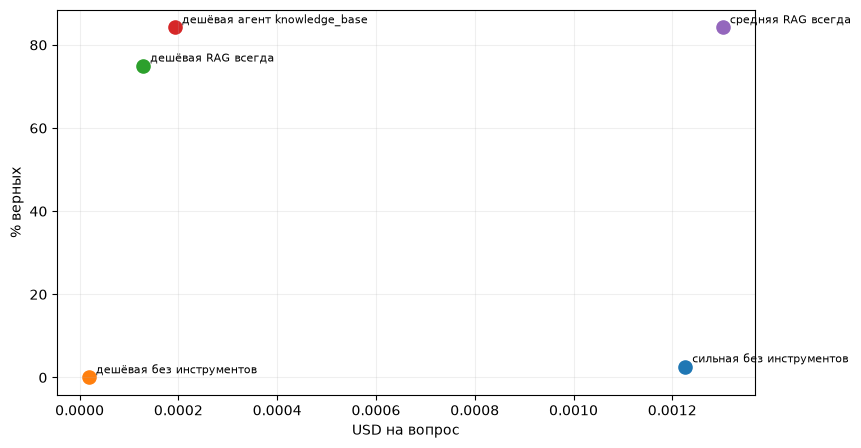

In [72]:
report=make_report(results);display(report)
fig,ax=plt.subplots(figsize=(9,5))
for _,r in report.iterrows():
    ax.scatter(r.price_question,r.accuracy*100,s=90)
    ax.annotate(r['config'],(r.price_question,r.accuracy*100),xytext=(5,3),textcoords='offset points',fontsize=8)
ax.set_xlabel('USD на вопрос')
ax.set_ylabel('% верных')
ax.grid(alpha=.2)
plt.savefig(IMG/'money_chart.png',dpi=160,bbox_inches='tight')
plt.show()

In [45]:
unknown=[{'id':f'unknown-{i}','question':q,'answer':''} for i,q in enumerate(UNANSWERABLE)]
refusal=[]
for name,fn,model in CONFIGS:
    unknown_df=run_eval(name,fn,model,unknown)
    known_df=results[results.config==name]
    refusal.append({'config':name,'correct_refusals_out_of_10':int(unknown_df.refused.sum()),
                    'false_refusals_answerable':int(known_df.refused.sum()),'known_total':len(known_df),
                    'unknown_errors':int(unknown_df.error.astype(bool).sum())})
    unknown_df.to_csv(DATA/('refusals_'+str(CONFIGS.index((name,fn,model)))+'.csv'),index=False)
refusal_table=pd.DataFrame(refusal);display(refusal_table)

2026-10-12 16:02:15,791 [WARNING][_recover]: Connection recovery failed (connection_manager.py:676)
Traceback (most recent call last):
  File "c:\Users\alex-\Documents\AI-agent\pythonProject4\venv\Lib\site-packages\pymilvus\decorators.py", line 419, in handler
    return func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\alex-\Documents\AI-agent\pythonProject4\venv\Lib\site-packages\pymilvus\client\grpc_handler.py", line 1462, in search
    return self._execute_search(
           ^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\alex-\Documents\AI-agent\pythonProject4\venv\Lib\site-packages\pymilvus\client\grpc_handler.py", line 1344, in _execute_search
    response = self._stub.Search(request, timeout=timeout, metadata=_api_level_md(context))
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\alex-\Documents\AI-agent\pythonProject4\venv\Lib\site-packages\grpc\_interceptor.py", line 276, in __call__
    response, ignor

,config,correct_refusals_out_of_10,false_refusals_answerable,known_total,unknown_errors
0,сильная без инструментов,10,70,76,0
1,дешёвая без инструментов,10,75,76,0
2,дешёвая RAG всегда,10,15,76,0
3,дешёвая агент knowledge_base,10,5,76,0
4,средняя RAG всегда,0,7,76,10


In [78]:
display(refusal_table)

,config,correct_refusals_out_of_10,false_refusals_answerable,known_total,unknown_errors
0,сильная без инструментов,10,70,76,0
1,дешёвая без инструментов,10,75,76,0
2,дешёвая RAG всегда,10,15,76,0
3,дешёвая агент knowledge_base,10,5,76,0
4,средняя RAG всегда,0,7,76,10


In [80]:
unknown_frames = []

for i, (name, fn, model) in enumerate(CONFIGS):
    path = DATA / f"refusals_{i}.csv"

    if not path.exists():
        print(f"Файл отсутствует: {path}")
        continue

    df = pd.read_csv(path)

    df["config"] = name

    unknown_frames.append(df)

unknown_results = pd.concat(
    unknown_frames,
    ignore_index=True
)

display(
    unknown_results[
        ["config", "id", "question", "answer",
         "refused", "error"]
    ].head(15)
)

,config,id,question,answer,refused,error
0,сильная без инструментов,unknown-0,Who won the 2026 Formula One World Drivers' Ch...,NOT_FOUND,True,NaN
1,сильная без инструментов,unknown-1,Which country won the Eurovision Song Contest ...,NOT_FOUND,True,NaN
2,сильная без инструментов,unknown-2,Which film won the Palme d'Or at the 2027 Cann...,NOT_FOUND,True,NaN
3,сильная без инструментов,unknown-3,What was the magnitude of the earthquake that ...,NOT_FOUND,True,NaN
4,сильная без инструментов,unknown-4,Which company first reached a ten trillion dol...,NOT_FOUND,True,NaN
5,сильная без инструментов,unknown-5,Who won the 2026 World Chess Championship matc...,NOT_FOUND,True,NaN
6,сильная без инструментов,unknown-6,What were the names of the judges at every 202...,NOT_FOUND,True,NaN
7,сильная без инструментов,unknown-7,How many printed tickets were sold at each ven...,NOT_FOUND,True,NaN
8,сильная без инструментов,unknown-8,What was the attendance at every single concer...,I cannot answer this question as it refers to ...,True,NaN
9,сильная без инструментов,unknown-9,Which weather station recorded the highest hou...,NOT_FOUND,True,NaN


In [81]:
# Пустые значения error считаем отсутствием ошибки
unknown_results["has_error"] = (
    unknown_results["error"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)
unknown_results["refused_bool"] = (
    unknown_results["refused"]
    .astype(str)
    .str.lower()
    .eq("true")
)
unknown_results["valid_refusal"] = (
    unknown_results["refused_bool"]
    & ~unknown_results["has_error"]
)
refusal_audit = unknown_results.groupby("config").agg(
    total_questions=("id", "size"),
    api_errors=("has_error", "sum"),
    valid_refusals=("valid_refusal", "sum"),
    refusals_including_errors=("refused_bool", "sum")
).reset_index()

display(refusal_audit)

,config,total_questions,api_errors,valid_refusals,refusals_including_errors
0,дешёвая RAG всегда,10,0,10,10
1,дешёвая агент knowledge_base,10,0,10,10
2,дешёвая без инструментов,10,0,10,10
3,сильная без инструментов,10,0,10,10
4,средняя RAG всегда,10,10,0,0


In [85]:
known_results = results.copy()

known_results["refused_bool"] = (
    known_results["refused"]
    .astype(str)
    .str.lower()
    .eq("true")
)

known_results["has_error"] = (
    known_results["error"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

known_audit = known_results.groupby("config").agg(
    known_total=("id", "size"),
    false_refusals=(
        "refused_bool",
        lambda s: int(s.sum())
    ),
    known_api_errors=("has_error", "sum")
).reset_index()

display(known_audit)

,config,known_total,false_refusals,known_api_errors
0,дешёвая RAG всегда,76,15,0
1,дешёвая агент knowledge_base,76,5,0
2,дешёвая без инструментов,76,75,0
3,сильная без инструментов,76,70,0
4,средняя RAG всегда,76,7,0


In [84]:
final_refusal_report = refusal_audit.merge(
    known_audit,
    on="config",
    how="left"
)

display(
    final_refusal_report[
        [
            "config",
            "total_questions",
            "valid_refusals",
            "api_errors",
            "known_total",
            "false_refusals",
            "known_api_errors"
        ]
    ]
)

final_refusal_report.to_csv(
    DATA / "refusal_report_verified.csv",
    index=False
)

,config,total_questions,valid_refusals,api_errors,known_total,false_refusals,known_api_errors
0,дешёвая RAG всегда,10,10,0,76,15,0
1,дешёвая агент knowledge_base,10,10,0,76,5,0
2,дешёвая без инструментов,10,10,0,76,75,0
3,сильная без инструментов,10,10,0,76,70,0
4,средняя RAG всегда,10,0,10,76,7,0


In [47]:
# Анализ провалов лучшей RAG-конфигурации (чтобы у каждой ошибки был trace выдачи)
rag_rows=results[results.config=='дешёвая RAG всегда']
fail=rag_rows[~rag_rows.correct].copy()
fail['failure_type']=np.where(fail.found,'нашёл, но ответ неверный','поиск не нашёл')
display(fail[['id','question','gold','answer','failure_type']].head(20))

,id,question,gold,answer,failure_type
154,fresh-3,What agreement did Ukraine and Romania sign in...,a strategic partnership agreement,strategic partnership agreement in the defense...,"нашёл, но ответ неверный"
156,fresh-5,How many people were killed in the car inciden...,two people,2,"нашёл, но ответ неверный"
160,fresh-10,How many people were killed in the February 18...,Twelve,12,"нашёл, но ответ неверный"
167,fresh-28,What was the number of people killed in the ma...,nine,9,"нашёл, но ответ неверный"
174,fresh-46,How many people died in the Moscow bombing on ...,five,5,"нашёл, но ответ неверный"
189,fresh-82,What was the death toll from the fire at a sho...,28 people,28,"нашёл, но ответ неверный"
190,fresh-87,Who is the President of Peru that was censured...,José Jerí,NOT_FOUND.,"нашёл, но ответ неверный"
208,ai-release-00,Какую модель OpenAI выпустила 5 марта 2026 год...,GPT‑5.4,NOT_FOUND.,"нашёл, но ответ неверный"
209,ai-release-01,Каков верхний предел контекстного окна GPT-5.4...,1M tokens,NOT_FOUND.,"нашёл, но ответ неверный"
210,ai-release-02,"Как называется функция поиска инструментов, до...",tool search,NOT_FOUND.,"нашёл, но ответ неверный"


In [48]:
for typ in ['поиск не нашёл','нашёл, но ответ неверный']:
    examples=fail[fail.failure_type==typ]
    if len(examples):
        q=examples.iloc[0]
        print('\nПРИМЕР:',typ,'ID:',q['id'],'\nВопрос:',q['question'],'\nЭталон:',q['gold'],'\nОтвет:',q['answer'])
        for h in search_db(q['question'],BEST_KIND,K):
            print('-',h['page'],'|',h['text'][:260])
    else:
        print('Пример категории не найден:',typ,'— нельзя выдумывать; смени набор или конфигурацию')


ПРИМЕР: поиск не нашёл ID: ai-release-13 
Вопрос: Какую оценку HLE-Verified Google указала для Gemini 3.8 Flash в сентябре 2026 года? 
Эталон: 54.9% 
Ответ: NOT_FOUND.
- google38 | We’re already using Gemini 3.8 Flash Cyber to secure code across Google. For example:
- google38 | Gemini 3.8 Flash delivers substantial gains from 3.7 Flash, often approaching the performance of higher-cost frontier models.
- google38 | Wiz found that Gemini 3.8 Flash Cyber achieves +7.5-9.7% higher recall on their internal penetration testing benchmark for a 2.3-5.2x lower cost compared to other leading frontier models.
- google35 | See what 4 builders are making with Gemini 3.8 Flash
- google38 | Gemini 3.8 Flash Cyber: expert cyber performance
- google38 | Gemini 3.8 Flash: our most intelligent workhorse model, delivering significant improvements from 3.7 Flash across software engineering, agentic tasks, and critical, multi-step reasoning in specialized domains. It is available at the same introductory 

In [55]:
task = next(
    q for q in tasks
    if q["id"] == "ai-release-13"
)

print("Источник:", task["page"])
print("Эталон:", task["answer"])
print("Цитата:", task["evidence"])

matching = [
    c for c in chunks[BEST_KIND]
    if c["page"] == task["page"]
    and (
        "54.9" in c["text"]
        or "HLE-Verified" in c["text"]
    )
]

print("Подходящих фрагментов:", len(matching))

for c in matching[:10]:
    print(c["text"][:1000])
    print("---")

Источник: google38
Эталон: 54.9%
Цитата: 3.8 Flash also achieves a 54.9% on HLE-Verified, demonstrating its ability to handle multi-step reasoning
Подходящих фрагментов: 1
Additionally, 3.8 Flash exhibits the dependability required for critical enterprise autonomy, across specialized knowledge domains . In quantitative and professional fields that require advanced analysis and reporting, 3.8 Flash outperforms 3.7 Flash and other frontier models in benchmarks like Vals Finance Agent V2 and Harvey's Legal Agent Benchmark . 3.8 Flash also achieves a 54.9% on HLE-Verified, demonstrating its ability to handle multi-step reasoning across STEM, humanities, and professional fields.
---


In [67]:
# нормализуем немного ответы, чтобы было точнее
NUMBER_WORDS = {
    "zero": "0", "one": "1", "two": "2",
    "three": "3", "four": "4", "five": "5",
    "six": "6", "seven": "7", "eight": "8",
    "nine": "9", "ten": "10", "eleven": "11",
    "twelve": "12", "thirteen": "13",
    "fourteen": "14", "fifteen": "15",
    "sixteen": "16", "seventeen": "17",
    "eighteen": "18", "nineteen": "19",
    "twenty": "20", "thirty": "30"
}


def extract_answer(text):
    """Извлекает ответ из тегов <answer> или после FINAL."""

    text = str(text).strip()

    match = re.search(
        r"<answer>(.*?)</answer>",
        text,
        flags=re.IGNORECASE | re.DOTALL
    )

    if match:
        return match.group(1).strip()

    match = re.search(
        r"FINAL:\s*(.*)",
        text,
        flags=re.IGNORECASE
    )

    if match:
        return match.group(1).strip()

    return text


def normalize_answer(text):
    """Нормализует текст для сравнения с эталоном."""

    text = extract_answer(text).casefold().strip()

    # Приводим 10-day, 10 days, 10 day к одному формату
    text = re.sub(
        r"\b(\d+)[-\s]+days?\b",
        r"\1 day",
        text
    )

    # Убираем английские артикли
    text = re.sub(
        r"\b(a|an|the)\b",
        " ",
        text
    )

    # Числительные словами преобразуем в цифры
    text = re.sub(
        r"\b(" + "|".join(NUMBER_WORDS) + r")\b",
        lambda m: NUMBER_WORDS[m.group()],
        text
    )

    # Убираем пунктуацию
    text = re.sub(r"[^\w\s]", " ", text)

    # Убираем лишние пробелы
    return " ".join(text.split())


def is_correct(answer, gold):
    """Проверяет, соответствует ли ответ модели эталону."""

    pred = normalize_answer(answer)
    target = normalize_answer(gold)

    if not pred or not target:
        return False

    # Отказы и ошибки не считаем правильным ответом
    if "not_found" in pred or "tool_error" in pred:
        return False

    # Проверка отрицаний остаётся консервативной
    if re.search(r"\b(not|never|no)\b", pred):
        return False

    return (
        pred == target
        or f" {target} " in f" {pred} "
    )

In [70]:
results = pd.read_csv(DATA / "answers_results.csv")
results["correct_old"] = results["correct"].copy()

# 3. Пересчитываем правильность ответов
results["correct"] = results.apply(
    lambda row: (
        False
        if pd.isna(row["answer"])
        else is_correct(
            row["answer"],
            row["gold"]
        )
    ),
    axis=1
)
changed = results.loc[
    results["correct"] != results["correct_old"]
].copy()
print("Всего проверено:", len(results))
print("Изменено оценок:", len(changed))

display(
    changed[
        [
            "config",
            "id",
            "gold",
            "answer",
            "correct_old",
            "correct"
        ]
    ]
)
results.to_csv(
    DATA / "answers_results_corrected.csv",
    index=False
)

# 7. Пересчитываем итоговые метрики
report = make_report(results)
display(report)

Всего проверено: 380
Изменено оценок: 12


,config,id,gold,answer,correct_old,correct
8,сильная без инструментов,fresh-10,Twelve,12,False,True
154,дешёвая RAG всегда,fresh-3,a strategic partnership agreement,strategic partnership agreement in the defense...,False,True
160,дешёвая RAG всегда,fresh-10,Twelve,12,False,True
167,дешёвая RAG всегда,fresh-28,nine,9,False,True
174,дешёвая RAG всегда,fresh-46,five,5,False,True
236,дешёвая агент knowledge_base,fresh-10,Twelve,12,False,True
243,дешёвая агент knowledge_base,fresh-28,nine,9,False,True
250,дешёвая агент knowledge_base,fresh-46,five,5,False,True
312,средняя RAG всегда,fresh-10,Twelve,<answer>12</answer>,False,True
319,средняя RAG всегда,fresh-28,nine,<answer>At least 9 people were killed (includi...,False,True


,config,model,n,accuracy,price_question,cost_total,price_correct
0,сильная без инструментов,anthropic/claude-sonnet-4.6,76,0.026316,0.001226,0.093201,0.046601
1,дешёвая без инструментов,openai/gpt-4o-mini,76,0.000000,0.000019,0.001424,NaN
2,дешёвая RAG всегда,openai/gpt-4o-mini,76,0.750000,0.000129,0.009775,0.000171
3,дешёвая агент knowledge_base,openai/gpt-4o-mini,76,0.842105,0.000193,0.014664,0.000229
4,средняя RAG всегда,anthropic/claude-haiku-4.5,76,0.842105,0.001303,0.098998,0.001547


## Шаг 4. Память: эпизоды, семантические факты, обновление, токены

In [49]:
JOURNAL=DATA/'episodes.jsonl';FACTS_JSON=DATA/'facts.json'
FACTS_COLLECTION='hw2_user_facts'
def log_episode(session,role,text):
    row={'session':session,'timestamp':datetime.now(timezone.utc).isoformat(),'role':role,'text':text}
    with JOURNAL.open('a',encoding='utf-8') as f:
        f.write(json.dumps(row,ensure_ascii=False)+'\n')
def load_facts():
    return json.loads(FACTS_JSON.read_text(encoding='utf-8')) if FACTS_JSON.exists() else {}
def store_facts(facts):
    FACTS_JSON.write_text(json.dumps(facts,ensure_ascii=False,indent=2),encoding='utf-8')
    if client.has_collection(FACTS_COLLECTION):client.drop_collection(FACTS_COLLECTION)
    if facts:
        rows=[{'page':'user','section':key,'url':'','text':f'{key}: {val}','ordinal':i} for i,(key,val) in enumerate(facts.items())]
        index_collection(FACTS_COLLECTION,rows,embed([row['text'] for row in rows]))

In [50]:
def recall_facts(question,k=3):
    if not client.has_collection(FACTS_COLLECTION):
        return []
    hits=client.search(collection_name=FACTS_COLLECTION,data=embed([question]).tolist(),limit=min(k,len(load_facts())),output_fields=['section','text'])[0]
    return [h['entity']['text'] for h in hits]
def extract_facts(dialog,previous):
    prompt=('Update a JSON dictionary of persistent user facts by category. Keep prior facts unless contradicted. '
            'Use categories name,city,profession,interest,preference as needed. New facts override older facts within the same category. '
            'No passwords, payment or third-party personal data. Return ONLY JSON object.\nPrevious: '
            +json.dumps(previous,ensure_ascii=False)+'\nSession:\n'+dialog)
    msg,_=chat([{'role':'user','content':prompt}],MODELS['cheap'],tag='extract_facts')
    raw=msg.get('content') or '{}';match=re.search(r'\{.*\}',raw,re.S)
    data=json.loads(match.group(0) if match else '{}')
    if not isinstance(data,dict):
        raise ValueError('Expected a JSON dictionary')
    return {str(k):str(v) for k,v in data.items() if isinstance(v,(str,int,float))}

In [51]:
def end_session(session,dialog):
    facts=extract_facts(dialog,load_facts());store_facts(facts)
    return facts
TEST_COLLECTION='hw2_memory_test'
def test_upsert(values):
    if client.has_collection(TEST_COLLECTION):client.drop_collection(TEST_COLLECTION)
    if values:
        client.create_collection(TEST_COLLECTION,dimension=3,metric_type='COSINE')
        client.insert(TEST_COLLECTION,[{'id':i,'vector':[1.,0.,0.],'text':v} for i,v in enumerate(values.values())])
        client.flush(TEST_COLLECTION)
def test_get():
    if not client.has_collection(TEST_COLLECTION):
        return []
    return [h['entity']['text'] for h in client.search(TEST_COLLECTION,data=[[1.,0.,0.]],limit=10,output_fields=['text'])[0]]
test_upsert({});assert test_get()==[]
test_upsert({'city':'Новосибирск'});assert 'Новосибирск' in test_get()
test_upsert({'city':'Казань'});assert 'Казань' in test_get() and 'Новосибирск' not in test_get()
client.drop_collection(TEST_COLLECTION)
print('3 теста памяти без LLM прошли: пустая / найденная / заменённая')

3 теста памяти без LLM прошли: пустая / найденная / заменённая


In [52]:
DEMO='demo_hw2'
for p in (JOURNAL,FACTS_JSON):
    p.unlink(missing_ok=True)
if client.has_collection(FACTS_COLLECTION):
    client.drop_collection(FACTS_COLLECTION)
def memory_turn(session,user_text):
    log_episode(session,'user',user_text)
    facts=recall_facts(user_text)
    msg,_=chat([{'role':'system','content':'Answer concisely. Known user facts: '+ '; '.join(facts)},
                {'role':'user','content':user_text}],MODELS['cheap'],tag='memory_turn')
    answer=msg.get('content') or '';log_episode(session,'assistant',answer)
    return answer

In [56]:
# Демонстрация двух отдельных сессий.
# Используем вымышленного пользователя, не собственные персональные данные.
s1='Меня зовут Лена. Я живу в Новосибирске и люблю хоккей.\nПосоветуй, какую спортивную тему почитать.'
print('Сессия 1:',memory_turn('session1',s1))
print('После сессии 1:',end_session('session1',s1))

Сессия 1: Рекомендую почитать о развитии хоккея в России, особенно о новосибирских командах, таких как "Сибирь". Также интересна тема влияния хоккея на культуру и общество в России.
После сессии 1: {'name': 'Лена', 'city': 'Новосибирск', 'interest': 'хоккей'}


In [57]:
s2='Какую спортивную тему ты посоветуешь мне теперь?'
print('Сессия 2:',memory_turn('session2',s2))
s2_update='Я больше не увлекаюсь хоккеем, теперь меня интересует футбол.'
print('Изменение:',memory_turn('session2',s2_update))
print('После сессии 2:',end_session('session2',s2+'\n'+s2_update))
print('Факты в Milvus:',recall_facts('Каким спортом увлекается Лена?'))
assert 'хокке' not in ' '.join(load_facts().values()).casefold(), 'Старый факт сохранился — проверь extract_facts и замени вручную перед отчётом' 

Сессия 2: Я рекомендую обратить внимание на женский хоккей. Это интересная и развивающаяся тема, особенно в России, где растет популярность женских команд. Вы можете следить за турнирами, новыми игроками и их успехами.
Изменение: Поняла, Лена! Футбол — тоже интересный вид спорта. Какой клуб или лига тебе нравится?
После сессии 2: {'name': 'Лена', 'city': 'Новосибирск', 'interest': 'футбол'}
Факты в Milvus: ['name: Лена', 'interest: футбол', 'city: Новосибирск']


In [62]:
# Сравнение входных токенов на диалоге >=10 РЕПЛИК (без API-вызовов):
encoder=tiktoken.get_encoding('cl100k_base')
def tok(s):
    return len(encoder.encode(s))
SCRIPT=['Привет, я Лена, живу в Новосибирске.', 'Я интересуюсь хоккеем.',
        'Что такое RAG?', 'А зачем нужен Milvus?', 'Расскажи про recall@k.',
        'Чем полезен гибридный поиск?', 'Как работает RRF?',
        'Как снизить стоимость LLM?', 'Как устроена память агента?',
        'В чём разница между эпизодической и семантической памятью?',
        'Теперь меня больше интересует футбол.', 'Что ты помнишь о моих интересах?']
assert len(SCRIPT)>=10

In [63]:
history=[]
token_rows=[]
example_facts=['Имя: Лена','Город: Новосибирск','Интерес: футбол']
for i,utterance in enumerate(SCRIPT,1):
    prompt_full='\n'.join(history+[utterance])
    prompt_memory='\n'.join(example_facts+history[-4:]+[utterance])
    token_rows.append({'turn':i,'full_history':tok(prompt_full),'window_plus_facts':tok(prompt_memory)})
    history += [utterance,'Спасибо за вопрос. Короткий ответ с опорой на источники.']

,turn,full_history,window_plus_facts
0,1,22,51
1,2,61,90
2,3,96,125
3,4,134,113
4,5,172,112
5,6,214,119
6,7,249,116
7,8,290,119
8,9,331,118
9,10,391,143


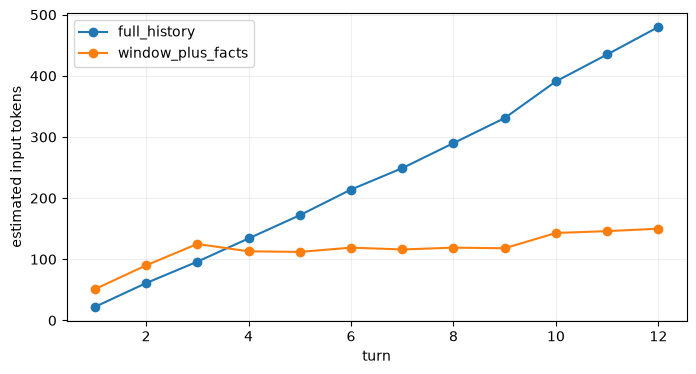

In [64]:
token_df=pd.DataFrame(token_rows);display(token_df)
token_df.plot(x='turn',y=['full_history','window_plus_facts'],marker='o',figsize=(8,4),ylabel='estimated input tokens')
plt.grid(alpha=.2)
plt.savefig(IMG/'memory_tokens.png',dpi=160,bbox_inches='tight')
plt.show()

In [71]:
INPUT_USD_PER_M = 0.15

total_tokens = token_df[
    ["full_history", "window_plus_facts"]
].sum()

costs = total_tokens * INPUT_USD_PER_M / 1_000_000

comparison = pd.DataFrame({
    "input_tokens": total_tokens,
    "estimated_input_usd": costs
})

display(comparison)

saved_tokens = (
    total_tokens["full_history"]
    - total_tokens["window_plus_facts"]
)

saving_pct = (
    saved_tokens / total_tokens["full_history"] * 100
)

print(f"Сэкономлено токенов: {saved_tokens}")
print(f"Экономия: {saving_pct:.2f}%")
print(f"Снижение расходов на вход: ${costs['full_history'] - costs['window_plus_facts']:.8f}")

,input_tokens,estimated_input_usd
full_history,2875,0.000431
window_plus_facts,1402,0.000210


Сэкономлено токенов: 1473
Экономия: 51.23%
Снижение расходов на вход: $0.00022095
